# Titanic | Hyperparameter Tuning

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
file_path = r"C:\Users\maria\Downloads\spaceship_titanic.csv"
raw_df = pd.read_csv(file_path)
raw_df.columns = raw_df.columns.str.strip()
print(raw_df.shape)
raw_df.head()

(8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
df = raw_df.copy()

# Cabin to Deck
df['Deck'] = df['Cabin'].astype('string').str[0]
valid_decks = set(list("ABCDEFGT"))
df['Deck'] = df['Deck'].where(df['Deck'].isin(valid_decks))

# Spending features
spend_cols = ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']
df['TotalSpend'] = df[spend_cols].sum(axis=1)
df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)

# Convert booleans
for col in ['CryoSleep','VIP','Transported']:
    if col in df.columns:
        df[col] = df[col].astype('bool').astype(int)

# Drop identifiers + raw 'Cabin'
for col in ['PassengerId','Name','Cabin']:
    if col in df.columns:
        df = df.drop(columns=[col])

# Drop rows with any NA
df = df.dropna()

# Categoricals
cat_cols = [c for c in ['HomePlanet','Destination','Deck'] if c in df.columns]
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print(df.shape)
df.head()

(7111, 22)


,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,TotalSpend,...,HomePlanet_Mars,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,0,39.0,0,0.0,0.0,0.0,0.0,0.0,0,0.0,...,False,False,True,True,False,False,False,False,False,False
1,0,24.0,0,109.0,9.0,25.0,549.0,44.0,1,736.0,...,False,False,True,False,False,False,False,True,False,False
2,0,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,10383.0,...,False,False,True,False,False,False,False,False,False,False
3,0,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,5176.0,...,False,False,True,False,False,False,False,False,False,False
4,0,16.0,0,303.0,70.0,151.0,565.0,2.0,1,1091.0,...,False,False,True,False,False,False,False,True,False,False


In [4]:
X = df.drop(columns=['Transported'])
y = df['Transported'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_train.shape, X_test.shape

((5688, 21), (1423, 21))

In [5]:
# KNN
knn_pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]).fit(X_train, y_train)
rf_base  = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train, y_train)
gb_base  = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

print("Baseline KNN acc:", accuracy_score(y_test, knn_pipe.predict(X_test)))
print("Baseline RF  acc:", accuracy_score(y_test, rf_base.predict(X_test)))
print("Baseline GB  acc:", accuracy_score(y_test, gb_base.predict(X_test)))

  File "C:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\maria\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\maria\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\maria\anaconda3\Lib\subprocess.

Baseline KNN acc: 0.7814476458186929
Baseline RF  acc: 0.7997189037245257
Baseline GB  acc: 0.8025298664792692


In [6]:
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

knn_grid = {
    'knn__n_neighbors': [3,5,7,9,11,15],
    'knn__weights': ['uniform','distance'],
    'knn__p': [1,2]  # Manhattan vs Euclidean
}

knn_gs = GridSearchCV(
    estimator=knn_pipe,
    param_grid=knn_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    refit=True
)

knn_gs.fit(X_train, y_train)
print("KNN best params:", knn_gs.best_params_)
print("KNN best CV acc:", f"{knn_gs.best_score_:.3f}")

y_pred = knn_gs.predict(X_test)
print("KNN test acc:", f"{accuracy_score(y_test, y_pred):.3f}")

KNN best params: {'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'uniform'}
KNN best CV acc: 0.778
KNN test acc: 0.776


In [7]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

rf_dist = {
    'n_estimators': np.arange(200, 801, 100),
    'max_depth': [None, 5, 8, 12, 16, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', 0.5, 0.8]
}

rf_rs = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_dist,
    n_iter=50,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    refit=True
)

rf_rs.fit(X_train, y_train)
print("RF best params:", rf_rs.best_params_)
print("RF best CV acc:", f"{rf_rs.best_score_:.3f}")

y_pred = rf_rs.predict(X_test)
print("RF test acc:", f"{accuracy_score(y_test, y_pred):.3f}")

RF best params: {'n_estimators': np.int64(200), 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 16}
RF best CV acc: 0.800
RF test acc: 0.805


In [8]:
gb = GradientBoostingClassifier(random_state=42)

gb_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.7, 0.85, 1.0]
}

gb_gs = GridSearchCV(
    estimator=gb,
    param_grid=gb_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    refit=True
)

gb_gs.fit(X_train, y_train)
print("GB best params:", gb_gs.best_params_)
print("GB best CV acc:", f"{gb_gs.best_score_:.3f}")

y_pred = gb_gs.predict(X_test)
print("GB test acc:", f"{accuracy_score(y_test, y_pred):.3f}")

GB best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.7}
GB best CV acc: 0.802
GB test acc: 0.810


In [9]:
logit_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logit', LogisticRegression(max_iter=2000))
])

# Use compatible solver/penalty combos to avoid errors
logit_grid = [
    {'logit__solver': ['liblinear'], 'logit__penalty': ['l1','l2'], 'logit__C': [0.01, 0.1, 1, 10]},
    {'logit__solver': ['lbfgs'],    'logit__penalty': ['l2'],        'logit__C': [0.01, 0.1, 1, 10]},
]

logit_gs = GridSearchCV(
    estimator=logit_pipe,
    param_grid=logit_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    refit=True
)

logit_gs.fit(X_train, y_train)
print("Logit best params:", logit_gs.best_params_)
print("Logit best CV acc:", f"{logit_gs.best_score_:.3f}")

y_pred = logit_gs.predict(X_test)
print("Logit test acc:", f"{accuracy_score(y_test, y_pred):.3f}")

Logit best params: {'logit__C': 10, 'logit__penalty': 'l1', 'logit__solver': 'liblinear'}
Logit best CV acc: 0.784
Logit test acc: 0.796


In [10]:
results = {
    "KNN (tuned)": accuracy_score(y_test, knn_gs.predict(X_test)),
    "RandomForest (tuned)": accuracy_score(y_test, rf_rs.predict(X_test)),
    "GradientBoosting (tuned)": accuracy_score(y_test, gb_gs.predict(X_test)),
    "LogisticRegression (tuned)": accuracy_score(y_test, logit_gs.predict(X_test)),
}

results_df = pd.DataFrame.from_dict(results, orient='index', columns=['Test_Accuracy'])
results_df = results_df.sort_values('Test_Accuracy', ascending=False)
display(results_df)

best_name = results_df.index[0]
print(f"\nBest tuned model on test set: {best_name} (acc = {results_df.iloc[0,0]:.3f})")

,Test_Accuracy
GradientBoosting (tuned),0.810260
RandomForest (tuned),0.805341
LogisticRegression (tuned),0.795502
KNN (tuned),0.775826



Best tuned model on test set: GradientBoosting (tuned) (acc = 0.810)


              precision    recall  f1-score   support

           0      0.825     0.785     0.804       707
           1      0.797     0.835     0.816       716

    accuracy                          0.810      1423
   macro avg      0.811     0.810     0.810      1423
weighted avg      0.811     0.810     0.810      1423



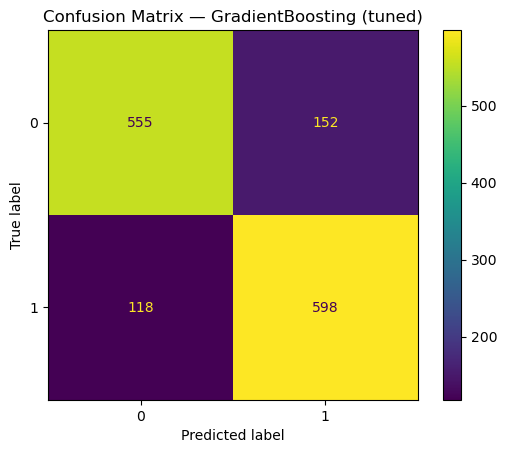

In [11]:
best_estimator = {
    "KNN (tuned)": knn_gs,
    "RandomForest (tuned)": rf_rs,
    "GradientBoosting (tuned)": gb_gs,
    "LogisticRegression (tuned)": logit_gs,
}[best_name]

y_pred_best = best_estimator.predict(X_test)
print(classification_report(y_test, y_pred_best, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()